In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

from experiments_utils import RESULTS_DIR

In [ ]:
ICS26_DIR = RESULTS_DIR / "ics26"
for d in ICS26_DIR.iterdir():
    print(d.name)

ics_quadratic
ics_shifted_gaussians


In [ ]:
# Publication-Quality Plot Settings
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 1.5,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)
PALETTE = "deep"
COLORS = sns.color_palette(PALETTE)

In [ ]:
def plot_error_with_log_log_fit(
    df,
    error_col1,
    error_col2,
    title1,
    title2,
    error_metric_col="ERROR_METRIC",
    skip_first_n=0,
):
    # drop rows where error_col1 or error_col2 is  or zero
    df = df[(df[error_col1] > 0) & (df[error_col2] > 0)]
    plt.figure(figsize=(16, 6))
    plt.subplot(1, 2, 1)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col1,
        hue="dim",
        style=error_metric_col,
        marker="o",
        palette=PALETTE,
    )
    for dim in df["dim"].unique():
        for e in df[error_metric_col].unique():
            subset = df[(df["dim"] == dim) & (df[error_metric_col] == e)]
            if len(subset) <= 1:
                continue
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col1].values)
            if skip_first_n > 0:
                X = X[skip_first_n:]
                y = y[skip_first_n:]
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (E={e}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
            plt.plot(
                np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label
            )
        plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col1.replace("_", " ").title())
    plt.title(title1)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 2, 2)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col2,
        hue="dim",
        style=error_metric_col,
        marker="o",
        palette=PALETTE,
    )
    for dim in df["dim"].unique():
        for e in df[error_metric_col].unique():
            subset = df[(df["dim"] == dim) & (df[error_metric_col] == e)]
            if len(subset) <= 1:
                continue
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col2].values)
            if skip_first_n > 0:
                X = X[skip_first_n:]
                y = y[skip_first_n:]
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (E={e}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col2.replace("_", " ").title())
    plt.title(title2)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)
    plt.show()


def plot_percentage_metrics(df):
    plt.figure(figsize=(24, 7))
    plt.subplot(1, 3, 1)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_out",
        hue="dim",
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ out (perct_out)")
    plt.title(r"$\%$ out vs Number of Cluster")
    plt.ylim(0, 100)
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 3, 2)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_in_good",
        hue="dim",
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ in-Good (perct_in_good)")
    plt.ylim(0, 100)
    plt.title(r"$\%$ in-Good vs Number of Cluster")
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 3, 3)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_in_bad",
        hue="dim",
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ in-Bad (perct_in_bad)")
    plt.ylim(0, 100)
    plt.title(r"$\%$ in-Bad vs Number of Cluster")
    plt.grid(True, which="both", ls="--", lw=0.5)
    plt.show()

# Problems

In [ ]:
prob_dir = ICS26_DIR / "ics_shifted_gaussians"
csv_path = prob_dir / "summary.csv"

df_problem = pd.read_csv(csv_path)
df_problem = df_problem.dropna(subset=["n_clusters"])

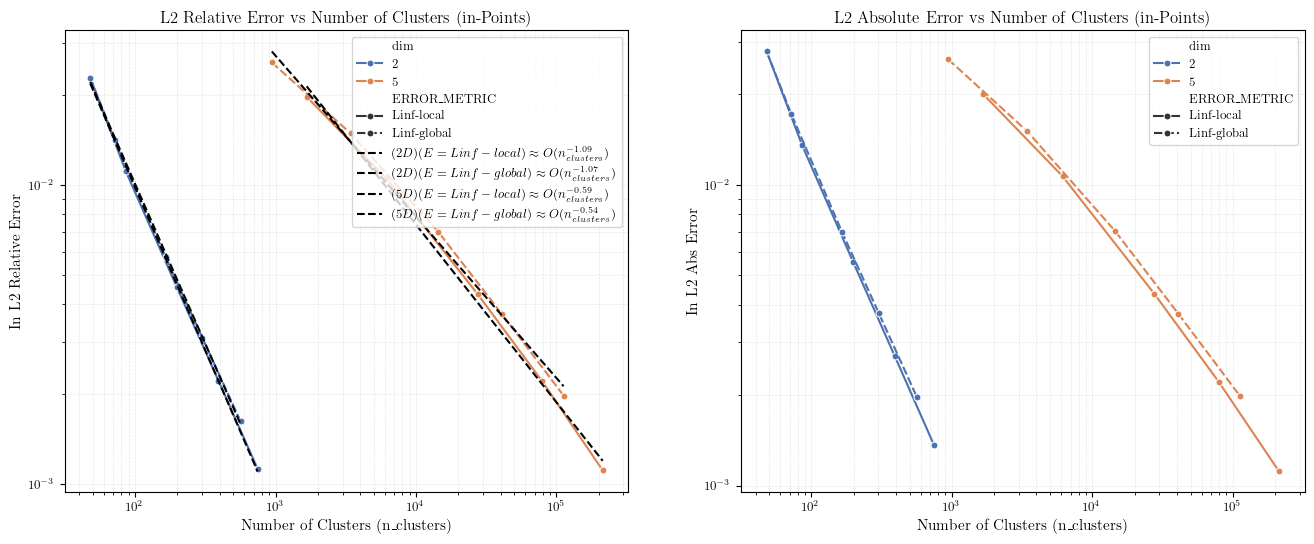

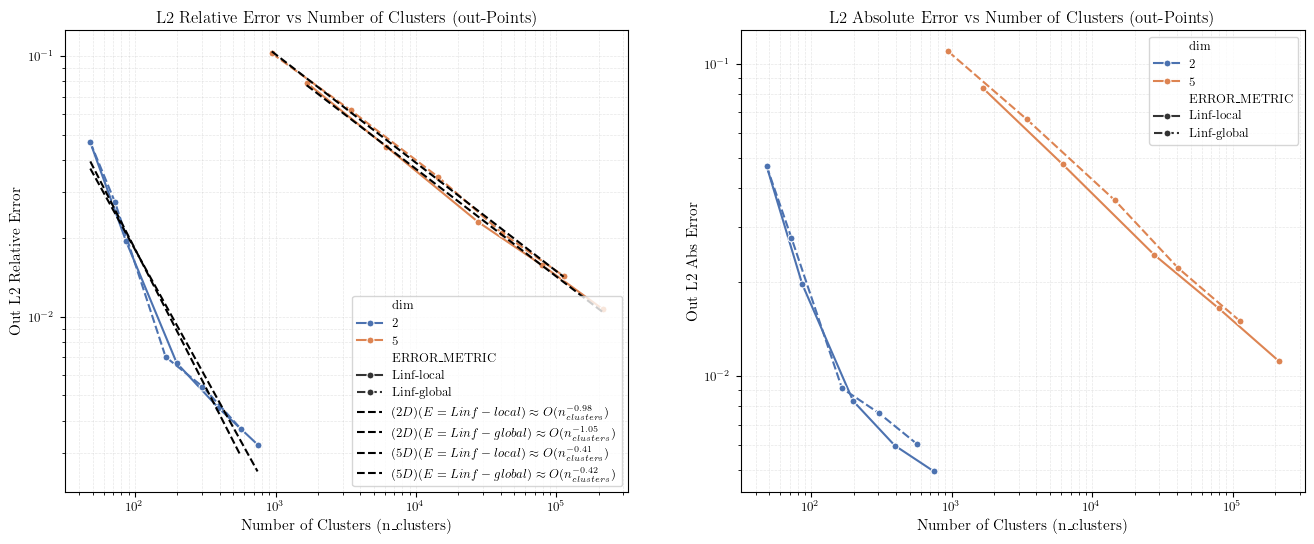

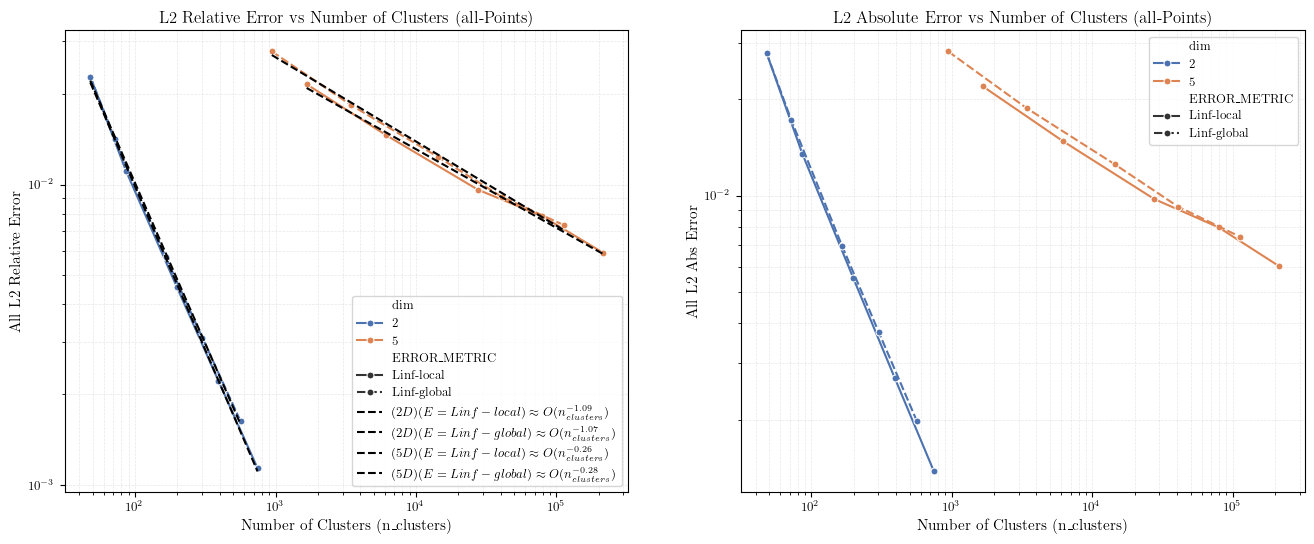

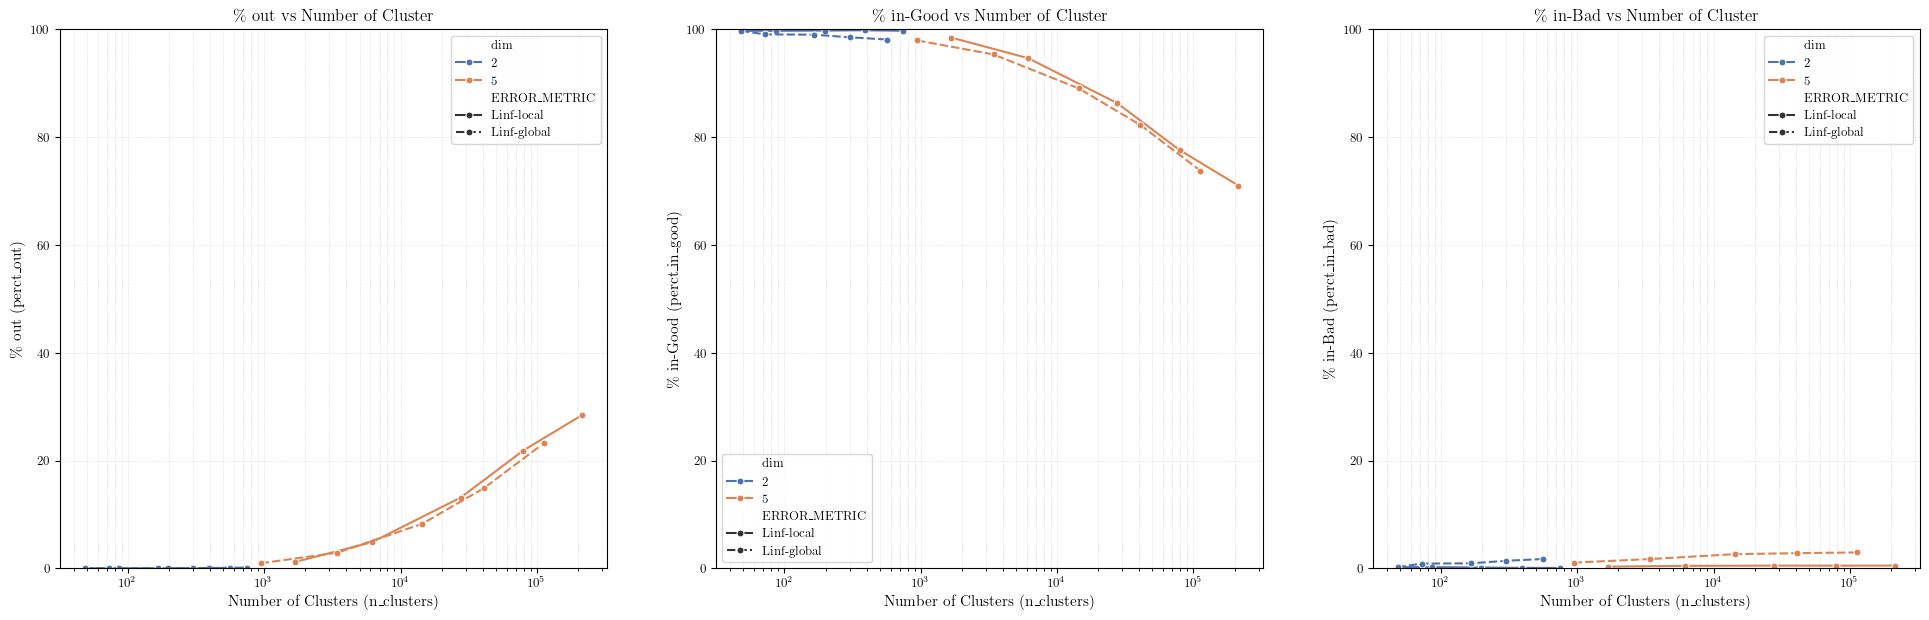

In [ ]:
if "hessian_estimation" in prob_dir.name:
    plot_error_with_log_log_fit(
        df_problem,
        "l2_rel_error",
        "l2_abs_error",
        "L2 Relative Error vs Number of Clusters",
        "L2 Absolute Error vs Number of Clusters",
        error_metric_col="metric",
        skip_first_n=1,
    )
else:
    plot_error_with_log_log_fit(
        df_problem,
        "in_l2_relative_error",
        "in_l2_abs_error",
        "L2 Relative Error vs Number of Clusters (in-Points)",
        "L2 Absolute Error vs Number of Clusters (in-Points)",
    )
    plot_error_with_log_log_fit(
        df_problem,
        "out_l2_relative_error",
        "out_l2_abs_error",
        "L2 Relative Error vs Number of Clusters (out-Points)",
        "L2 Absolute Error vs Number of Clusters (out-Points)",
    )
    plot_error_with_log_log_fit(
        df_problem,
        "all_l2_relative_error",
        "all_l2_abs_error",
        "L2 Relative Error vs Number of Clusters (all-Points)",
        "L2 Absolute Error vs Number of Clusters (all-Points)",
    )
    plot_percentage_metrics(df_problem)

In [ ]:
def get_renamed_df(df):
    rename_cols = {
        "dim": "D",
        "f_dim": "F Dim",
        "tol": "tol",
        "ERROR_METRIC": "Error Metric",
        "n_clusters": "N Src",
        "in_l2_relative_error": "L2 Rel Err (In)",
        "in_l2_abs_error": "L2 Abs Err (In)",
        "in_ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (In)",
        "in_ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (In)",
        "out_l2_relative_error": "L2 Rel Err (Out)",
        "out_l2_abs_error": "L2 Abs Err (Out)",
        "out_ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (Out)",
        "out_ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (Out)",
        "perct_out": "% Out",
        "perct_in_good": "% In-Good",
        "perct_in_bad": "% In-Bad",
        "n_out": "N Out",
        "n_train": "N Train",
        "n_test": "N Test",
        "all_l2_relative_error": "L2 Rel Err (All)",
        "all_l2_abs_error": "L2 Abs Err (All)",
        "all_ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (All)",
        "all_ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (All)",
        "N_INIT_CLUSTERS": "Init Clusters",
        "N_MIN_PER_CLUSTER": "Min Per Cluster",
    }
    df_renamed = df.rename(columns=rename_cols)[list(rename_cols.values())]
    return df_renamed


# if "hessian_estimation" in prob_dir.name:
display(get_renamed_df(df_problem))
get_renamed_df(df_problem).to_clipboard(index=False)

,D,F Dim,tol,Error Metric,N Src,L2 Rel Err (In),L2 Abs Err (In),Ptwise Max Rel L-inf Err (In),Ptwise Median Rel L-inf Err (In),L2 Rel Err (Out),...,% In-Bad,N Out,N Train,N Test,L2 Rel Err (All),L2 Abs Err (All),Ptwise Max Rel L-inf Err (All),Ptwise Median Rel L-inf Err (All),Init Clusters,Min Per Cluster
0,2,1,0.100,Linf-local,48,0.022895,0.027807,0.148421,0.005433,0.046691,...,0.229586,9,84500,42250,0.022901,0.027812,0.148421,0.005433,42,169
1,2,1,0.100,Linf-global,48,0.022895,0.027807,0.148421,0.005433,0.046691,...,0.229586,9,84500,42250,0.022901,0.027812,0.148421,0.005433,42,169
2,2,1,0.050,Linf-local,86,0.011142,0.013532,0.075606,0.002792,0.019595,...,0.236686,7,84500,42250,0.011143,0.013533,0.075606,0.002792,42,169
3,2,1,0.050,Linf-global,72,0.014149,0.017185,0.091139,0.003659,0.027521,...,0.894675,10,84500,42250,0.014153,0.017188,0.091139,0.003659,42,169
4,2,1,0.020,Linf-local,198,0.004568,0.005548,0.031417,0.001316,0.006652,...,0.163314,18,84500,42250,0.004569,0.005549,0.031417,0.001316,42,169
5,2,1,0.020,Linf-global,165,0.005747,0.006980,0.037906,0.001726,0.007022,...,0.946746,13,84500,42250,0.005748,0.006981,0.037906,0.001727,42,169
6,2,1,0.010,Linf-global,302,0.003082,0.003743,0.019414,0.000998,0.005406,...,1.417751,18,84500,42250,0.003084,0.003745,0.019414,0.000998,42,169
7,2,1,0.010,Linf-local,392,0.002219,0.002695,0.014385,0.000675,0.004479,...,0.101775,22,84500,42250,0.002221,0.002698,0.014385,0.000675,42,169
8,2,1,0.005,Linf-global,564,0.001621,0.001968,0.011283,0.000549,0.003728,...,1.753846,49,84500,42250,0.001628,0.001977,0.011283,0.000550,42,169
9,2,1,0.005,Linf-local,745,0.001125,0.001366,0.006623,0.000380,0.003239,...,0.085207,68,84500,42250,0.001136,0.001379,0.006623,0.000382,42,169


In [ ]:
# Fit a line for log-log data of n_clusters vs in_l2_relative_error for each dim and error metric, store the results in a dict
error_cols = [
    "in_l2_relative_error",
    "in_l2_abs_error",
    "in_ptwise_max_rel_error_linf",
    "in_ptwise_median_rel_error_linf",
    "out_l2_relative_error",
    "out_l2_abs_error",
    "out_ptwise_max_rel_error_linf",
    "out_ptwise_median_rel_error_linf",
    "all_l2_relative_error",
    "all_l2_abs_error",
    "all_ptwise_max_rel_error_linf",
    "all_ptwise_median_rel_error_linf",
]
results_list = []

for dim in df_problem["dim"].unique():
    for error_metric in df_problem["ERROR_METRIC"].unique():
        subset = df_problem[
            (df_problem["dim"] == dim) & (df_problem["ERROR_METRIC"] == error_metric)
        ]

        # Skip if not enough points to fit a line
        if len(subset) <= 1:
            continue

        # Initialize the row with metadata
        row = {"dim": dim, "ERROR_METRIC": error_metric}

        X = np.log(subset["n_clusters"].values).reshape(-1, 1)

        for error_col in error_cols:
            # Handle potential zeros/nans in log if necessary,
            # assuming data is clean here as per your snippet
            y = np.log(subset[error_col].values)

            model = LinearRegression()
            model.fit(X, y)

            # Store the slope with the column name as the key
            row[error_col] = model.coef_[0]

        results_list.append(row)

# Create the pivoted DataFrame directly
fit_results_df = pd.DataFrame.from_dict(fit_results, orient="index", columns=["slope"]) # type: ignore
fit_results_df.index = pd.MultiIndex.from_tuples(
    fit_results_df.index, names=["dim", "ERROR_METRIC", "error_col"]
)

# 2. Pivot: Move 'dim' and 'ERROR_METRIC' to columns
final_df = fit_results_df.unstack(level=["dim", "ERROR_METRIC"])

# 3. Cleanup: Remove 'slope' level
final_df.columns = final_df.columns.droplevel(0)

# 4. Rename columns to "2D-metric" format
final_df.columns = [f"{dim}D-{metric}" for dim, metric in final_df.columns]

display(final_df)
final_df.to_clipboard()

,2D-Linf-local,2D-Linf-global,5D-Linf-local,5D-Linf-global
error_col,,,,
all_l2_abs_error,-1.087876,-1.069788,-0.261961,-0.280556
all_l2_relative_error,-1.087876,-1.069788,-0.261961,-0.280556
all_ptwise_max_rel_error_linf,-1.124228,-1.052070,-0.305581,-0.300884
all_ptwise_median_rel_error_linf,-0.960432,-0.923336,0.082284,0.057845
in_l2_abs_error,-1.090666,-1.071334,-0.597226,-0.541694
in_l2_relative_error,-1.090512,-1.071162,-0.594941,-0.539689
in_ptwise_max_rel_error_linf,-1.124228,-1.052070,-0.543981,-0.491220
in_ptwise_median_rel_error_linf,-0.961561,-0.923952,-0.501911,-0.442972
out_l2_abs_error,-0.814168,-0.848444,-0.416183,-0.420843
